### Data loading

In [2]:
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

C:\Users\varsh\AppData\Local\Temp\ipykernel_2080\3472909191.py:3: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [3]:
df = pd.read_csv(r"D:\vscode\P3_job_placement\HR_Job_Placement_Dataset.csv")

In [4]:
df2 =df.copy()

In [6]:
df.shape

(51500, 26)

In [8]:
df.head()

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  object 
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  object 
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  object 
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  obj

In [10]:
df.describe()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months
count,51500.000000,48919.000000,49435.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,49918.000000,50403.000000
mean,27.505456,70.002505,72.060636,74.010825,68.027499,64.005715,66.106692,73.937491,1.400136,1.494117,4.844616,8.002649,20.095457,3.056187
std,4.025385,7.976314,7.916654,6.945579,11.855145,9.922397,9.907488,11.794258,1.184387,1.375508,2.125294,3.133792,24.852660,4.431784
min,21.000000,50.000000,50.000000,55.000000,40.000000,40.000000,45.000000,45.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000
25%,24.000000,64.574733,66.720058,69.305041,59.935988,57.204237,59.252271,65.851924,1.000000,0.000000,3.325635,5.672655,0.000000,0.000000
50%,27.000000,69.971210,72.014383,73.998187,67.986042,63.972079,66.033268,74.001772,1.000000,1.000000,4.807598,7.857337,15.000000,0.000000
75%,31.000000,75.389057,77.389894,78.707827,76.049235,70.727134,72.840985,82.112773,2.000000,2.000000,6.297570,10.093509,30.000000,6.000000
max,34.000000,95.000000,95.000000,95.000000,100.000000,100.000000,100.000000,100.000000,8.000000,5.000000,13.844566,26.524634,90.000000,18.000000


In [11]:
df.isnull().mean()*100

age_years                     0.000000
gender                        0.000000
ssc_percentage                5.011650
hsc_percentage                4.009709
degree_percentage             0.000000
degree_specialization         0.000000
technical_score               0.000000
aptitude_score                0.000000
communication_score           0.000000
skills_match_percentage       0.000000
certifications_count          0.000000
internship_experience         0.000000
years_of_experience           0.000000
career_switch_willingness    16.438835
relevant_experience          16.361165
previous_ctc_lpa              0.000000
expected_ctc_lpa              0.000000
company_tier                  0.000000
job_role_match               11.904854
competition_level             0.000000
bond_requirement              0.000000
notice_period_days            3.071845
layoff_history               16.440777
employment_gap_months         2.130097
relocation_willingness       16.456311
status                   

In [5]:
df[df.duplicated()]

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
50000,29,Male,82.777504,55.403494,72.608382,Computer Science,85.730203,72.426358,51.770110,97.577679,...,9.093150,Tier 2,Matched,Medium,Not Required,15.0,No,0.0,Not Willing,Placed
50001,27,male,54.905068,80.120543,77.037600,Computer Science,54.166158,61.548708,65.307474,66.014409,...,7.292962,Tier 2,Matched,Low,Not Required,15.0,No,0.0,NaN,Not Placed
50003,21,Female,62.638945,60.735432,77.153040,Computer Science,59.987920,59.017158,56.717055,73.084570,...,7.108719,Tier 1,Matched,Low,Not Required,0.0,No,0.0,Not Willing,Not Placed
50004,25,Male,59.360622,70.230456,85.377955,Mechanical,65.678132,83.774928,79.334052,80.443948,...,10.555169,Tier 1,Matched,Low,Required,60.0,No,0.0,Not Willing,Not Placed
50005,22,Female,72.019465,79.009356,67.887885,Others,56.213118,73.397254,48.806828,91.301263,...,7.938697,Tier 1,Matched,Low,Not Required,60.0,No,12.0,Willing,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51494,26,Female,69.562323,63.891266,75.931809,Computer Science,59.990409,51.169120,73.769113,68.913006,...,7.910303,Tier 2,NaN,Medium,Not Required,0.0,No,6.0,Not Willing,Not Placed
51495,24,Female,65.747180,72.063946,72.247881,Electronics,55.923057,73.208032,69.108895,63.992488,...,6.315211,Tier 1,Matched,Low,Required,0.0,No,3.0,NaN,Not Placed
51496,22,Male,61.921459,66.729203,55.000000,Others,69.525121,70.245612,54.959868,88.514232,...,8.655391,Tier 1,Matched,Medium,Not Required,60.0,No,0.0,Not Willing,Placed
51498,29,Female,77.327209,56.629227,69.735374,Mechanical,48.270078,61.171900,71.650243,76.318681,...,9.617279,Tier 2,Matched,Medium,Not Required,0.0,Yes,0.0,Willing,Not Placed


### Handling missing values

In [6]:
num_col = ["ssc_percentage","hsc_percentage","notice_period_days" ,"employment_gap_months"]
for i in num_col:
    df = df.fillna(df[num_col].median())

In [7]:
mode_col =["career_switch_willingness","relevant_experience","job_role_match","layoff_history","relocation_willingness"]
for i in mode_col:
    df[i] = df[i].fillna(df[i].mode()[0])

In [15]:
df.isnull().sum()

age_years                    0
gender                       0
ssc_percentage               0
hsc_percentage               0
degree_percentage            0
degree_specialization        0
technical_score              0
aptitude_score               0
communication_score          0
skills_match_percentage      0
certifications_count         0
internship_experience        0
years_of_experience          0
career_switch_willingness    0
relevant_experience          0
previous_ctc_lpa             0
expected_ctc_lpa             0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
notice_period_days           0
layoff_history               0
employment_gap_months        0
relocation_willingness       0
status                       0
dtype: int64

### Handling duplicates

In [8]:
df=df.drop_duplicates()

In [9]:
cat_col =['gender', 'internship_experience',
       'career_switch_willingness', 'relevant_experience',
       'job_role_match', 'bond_requirement',
       'layoff_history', 'relocation_willingness', 'status']

In [10]:
for i in cat_col:
    df[i] = df[i].astype("string").str.strip().str.title()

In [11]:
for i in cat_col:
     df[i] = df[i].str.strip()

### EDA

In [20]:
EDA = ProfileReport(df, title="EDA")


In [21]:
EDA

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 26/26 [00:02<00:00, 12.06it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
df["interview_score"] = df[["technical_score","aptitude_score","communication_score"]].mean(axis=1)

In [27]:
df["placed"] = (df['status']== "Placed").astype(int)

In [26]:
%matplotlib inline

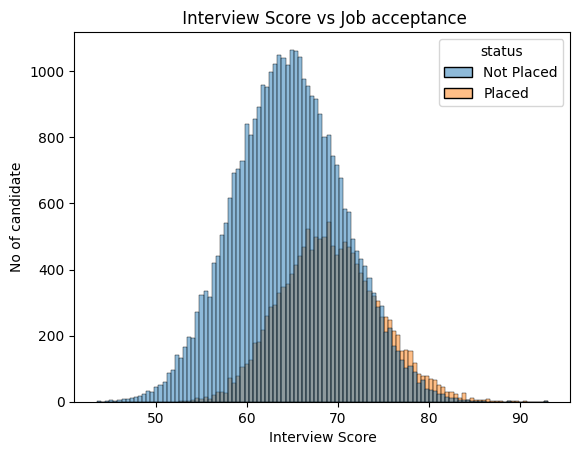

In [27]:
#Interview score vs job acceptance
sns.histplot(data=df, x="interview_score",hue="status" )
plt.title(" Interview Score vs Job acceptance")
plt.xlabel("Interview Score")
plt.ylabel("No of candidate")
plt.show()


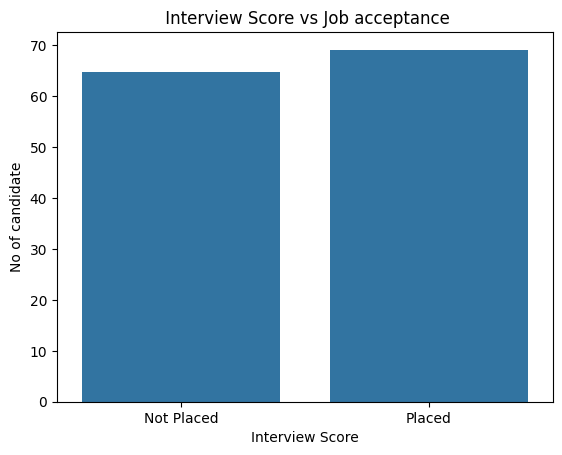

In [29]:
#Interview score vs job acceptance
sns.barplot(data=df,x="status",y="interview_score",errorbar=None )
plt.title(" Interview Score vs Job acceptance")
plt.xlabel("Interview Score")
plt.ylabel("No of candidate")
plt.show()


In [33]:
df["skills_range"] = pd.cut(
    df["skills_match_percentage"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=['0-20','20-40','40-60','60-80','80-100'],
    include_lowest=True
)


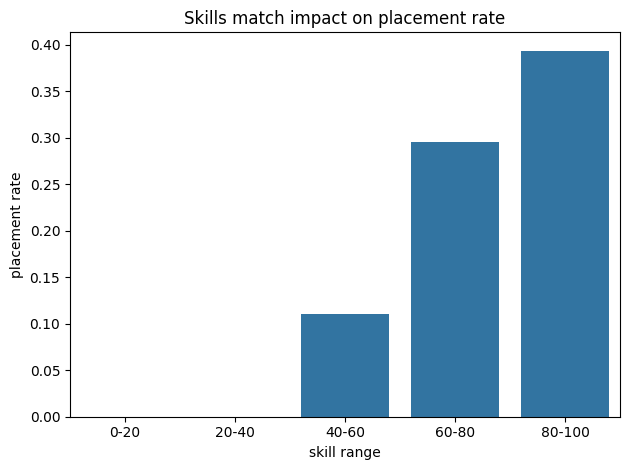

In [30]:
#Skills match impact  on placement rate
%matplotlib inline
sns.barplot(data=df , x="skills_range", y="status",estimator="mean",errorbar=None)
plt.title("Skills match impact on placement rate")
plt.xlabel("skill range")
plt.ylabel("placement rate")
plt.tight_layout()
plt.show()

In [31]:
df["placed"] = df["status"].map({
    "Placed": 1,
    "Not Placed": 0
})

In [63]:
acceptance_rate = (df.groupby("company_tier")["placed"].mean().mul(100).reset_index(name="acceptance_rate"))

In [54]:
df.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status', 'interview_score', 'placed', 'skills_range',
       'acceptance_rate'],
      dtype='object')

In [56]:
df["company_tier"] = df["company_tier"].str.strip()

In [61]:
df["company_tier"].value_counts()

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64

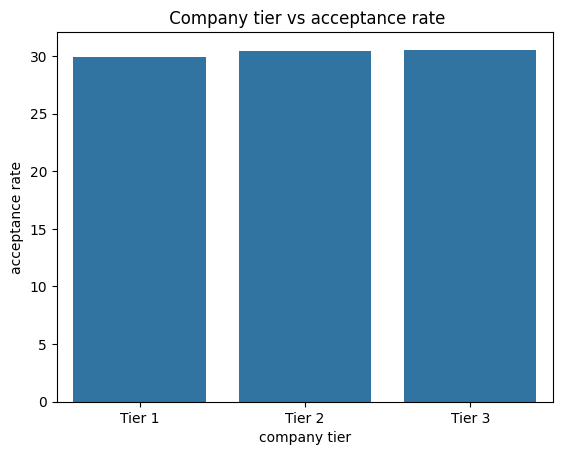

In [64]:
#Company tier vs acceptance rate

sns.barplot(data=acceptance_rate, x="company_tier", y="acceptance_rate",errorbar=None)
plt.title(" Company tier vs acceptance rate")
plt.xlabel("company tier")
plt.ylabel("acceptance rate")
plt.show()

In [67]:

placement_proba = (df.groupby("years_of_experience")["placed"].mean())

In [69]:
print(type(placement_proba))
print(placement_proba.head())

<class 'pandas.core.series.Series'>
years_of_experience
0    0.137816
1    0.241448
2    0.361253
3    0.490235
4    0.577053
Name: placed, dtype: float64


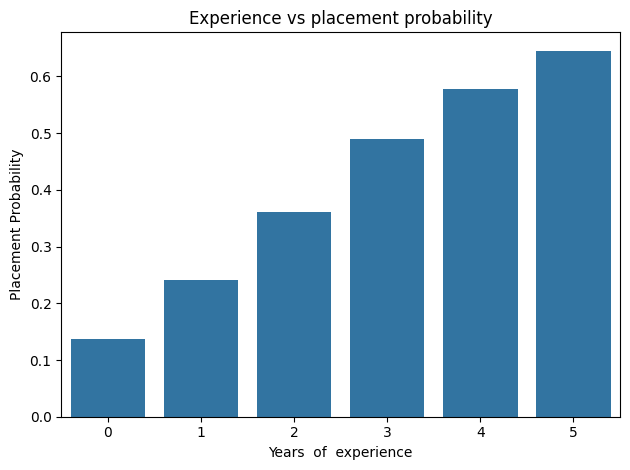

In [71]:
#Experience vs placement probability

sns.barplot(x =placement_proba.index , y =placement_proba.values,errorbar=None)
plt.title("Experience vs placement probability")
plt.xlabel("Years  of  experience")
plt.ylabel("Placement Probability")
plt.tight_layout()
plt.show()

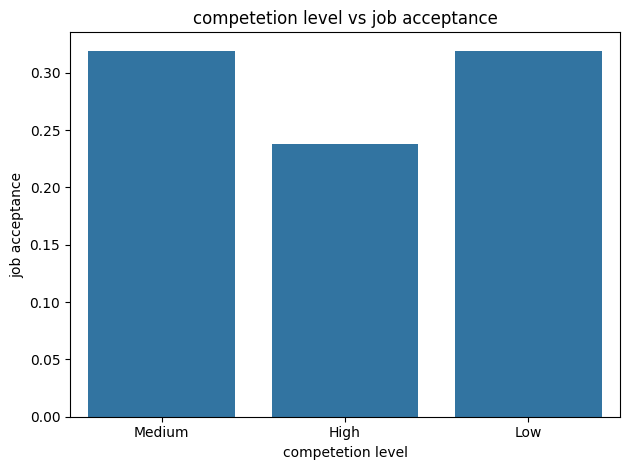

In [72]:
#competetion level vs job acceptance

sns.barplot(data=df , x="competition_level", y="placed",errorbar=None)
plt.title("competetion level vs job acceptance")
plt.xlabel("competetion level")
plt.ylabel("job acceptance")
plt.tight_layout()
plt.show()

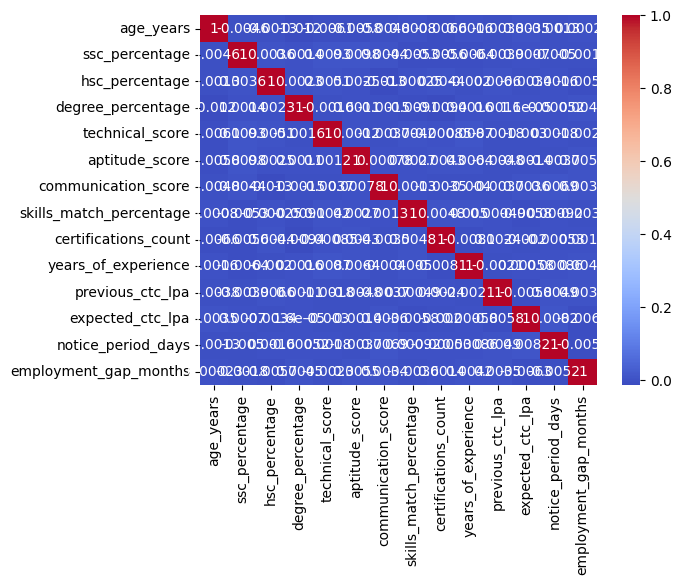

In [73]:
#correlation between numerical values
num_columns= ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage',
       'technical_score', 'aptitude_score', 'communication_score',
       'skills_match_percentage', 'certifications_count',
       'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa',
       'notice_period_days', 'employment_gap_months']

corr= df[num_columns].corr()
sns.heatmap(corr,annot=True ,cmap="coolwarm")
plt.show()

In [22]:
df2["placed"]=(df["status"]== 'placed')

In [23]:
df2["academic_average"]=df2[["ssc_percentage","hsc_percentage","degree_percentage"]].mean(axis=1)

In [33]:
df2["interview_score"] = df2[["technical_score","aptitude_score","communication_score"]].mean(axis=1)

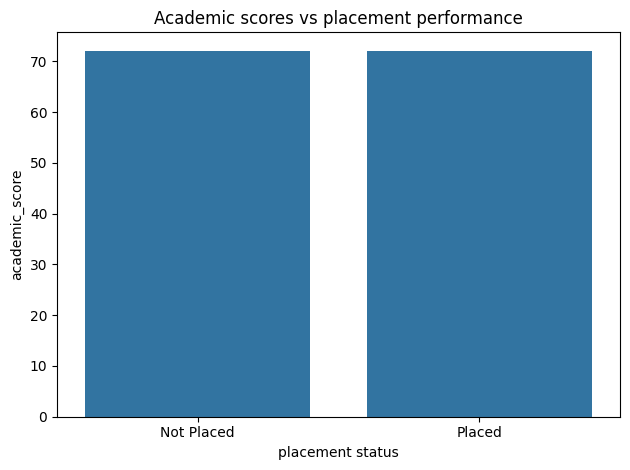

In [81]:
#Academic scores vs placement performance
sns.barplot(data=df2, x="status", y = "academic_average", errorbar=None)
plt.title("Academic scores vs placement performance")
plt.xlabel("placement status")
plt.ylabel("academic_score")
plt.tight_layout()
plt.show()

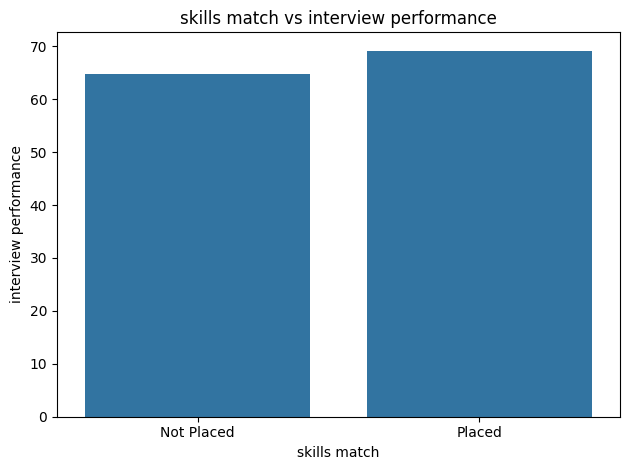

In [82]:
#skills match vs interview performance
sns.barplot(data=df2, x="status", y = "interview_score", errorbar=None)
plt.title("skills match vs interview performance")
plt.xlabel("skills match")
plt.ylabel("interview performance")
plt.tight_layout()
plt.show()

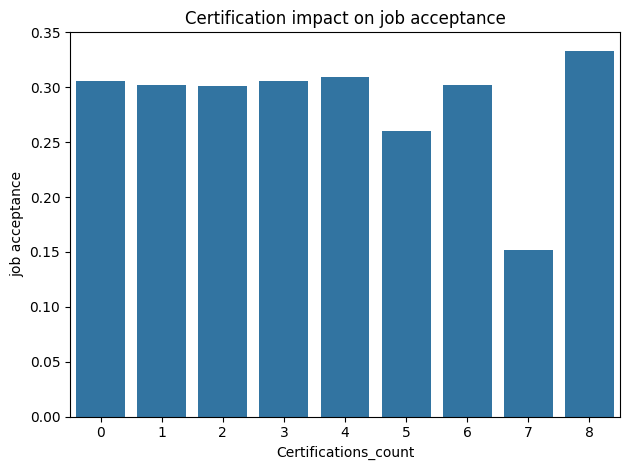

In [84]:
#Certification impact on job acceptance
sns.barplot(data=df, x= "certifications_count",y="placed", errorbar=None)
plt.title("Certification impact on job acceptance")
plt.xlabel("Certifications_count")
plt.ylabel("job acceptance")
plt.tight_layout()
plt.show()

In [34]:
df["acceptance_rate"]=df["placed"].mean()*100

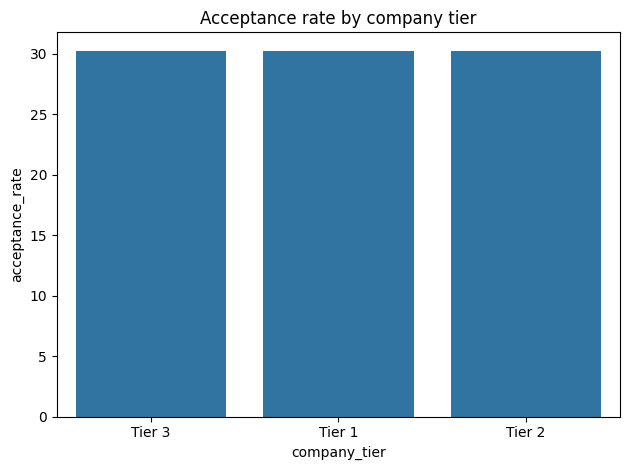

In [88]:
#Acceptance rate by company tier
sns.barplot(data=df, x= "company_tier",y="acceptance_rate", errorbar=None)
plt.title("Acceptance rate by company tier")
plt.xlabel("company_tier")
plt.ylabel("acceptance_rate")
plt.tight_layout()
plt.show()

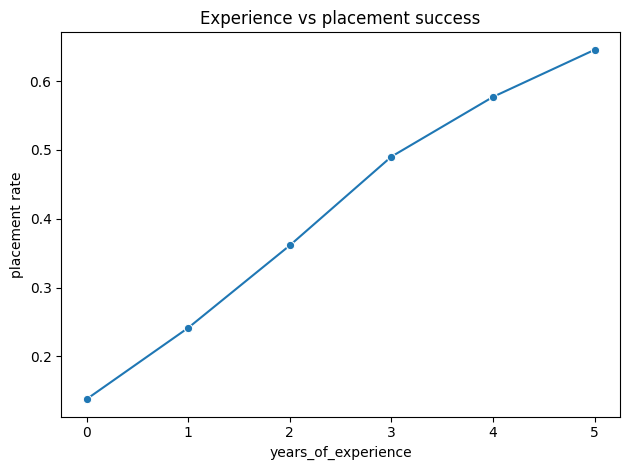

In [89]:
#Experience vs placement success
sns.lineplot(data=df, x= "years_of_experience",y="placed", estimator="mean", errorbar=None,marker="o")
plt.title("Experience vs placement success")
plt.xlabel("years_of_experience")
plt.ylabel("placement rate")
plt.tight_layout()
plt.show()

In [90]:
df["placement_proba"]=df["status"].eq("Placed").mean()

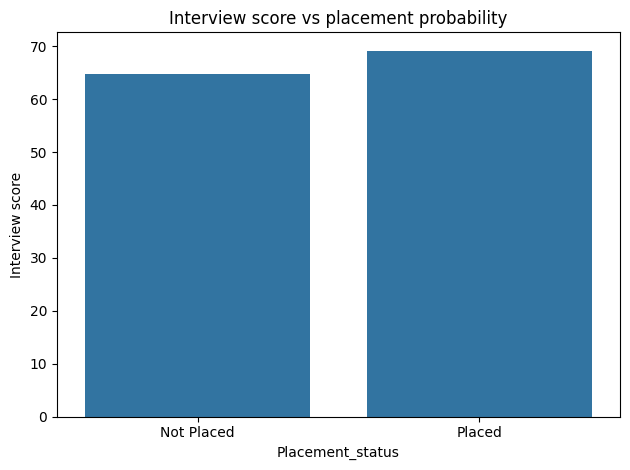

In [91]:
# Interview score vs placement probability
sns.barplot(data=df2, x="status", y="interview_score",errorbar=None)
plt.title("Interview score vs placement probability")
plt.xlabel("Placement_status")
plt.ylabel("Interview score")
plt.tight_layout()
plt.show()

In [92]:
df.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status', 'interview_score', 'placed', 'skills_range',
       'acceptance_rate', 'placement_proba'],
      dtype='object')

### Encoding

In [12]:
enc= ["gender","internship_experience","career_switch_willingness","relevant_experience","job_role_match","bond_requirement","layoff_history","relocation_willingness","status"]

In [13]:
for i in enc:
    labelenc= LabelEncoder()
    df[i]=labelenc.fit_transform(df[i])

In [95]:
df.head()

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,interview_score,placed,skills_range,acceptance_rate,placement_proba
0,27,1,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,15.0,0,18.0,0,0,70.754233,0,60-80,30.272923,0.302729
1,24,1,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,0.0,0,0.0,0,0,62.532418,0,60-80,30.272923,0.302729
2,33,0,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,0.0,0,3.0,0,1,70.175622,1,60-80,30.272923,0.302729
3,31,1,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,0.0,1,6.0,1,0,64.539376,0,60-80,30.272923,0.302729
4,28,1,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,0.0,0,3.0,1,0,65.146274,0,80-100,30.272923,0.302729


In [14]:
df.select_dtypes(include="object").nunique()

degree_specialization    5
company_tier             6
competition_level        3
dtype: int64

In [ ]:
oneenc = ["degree_specialization","company_tier","competition_level"]
for i in oneenc:
    df[i] = df[i].str.strip()
ohe = OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False)
encoded = ohe.fit_transform(df[oneenc])
encoded_df = pd.DataFrame(encoded,columns=ohe.get_feature_names_out(oneenc),index=df.index)

KeyError: 'degree_specialization'

In [38]:
df = pd.concat([df.drop(columns=oneenc), encoded_df], axis=1)

KeyError: "['degree_specialization', 'company_tier', 'competition_level'] not found in axis"

### Feature engineering

In [17]:
df["experience_category"]= np.select(
   [ df["years_of_experience"]==0,
    df["years_of_experience"].between(1,3),
    df["years_of_experience"]>=4],
    [0,1,2],
    default=-1)

In [18]:
df["academic_average"]= df[["ssc_percentage","hsc_percentage","degree_percentage"]].mean(axis=1)

In [19]:
df["academic_performance"]= np.select(
   [ df["academic_average"] < 60,
    df["academic_average"].between(60,80),
    df["academic_average"]>=80],
    [0,1,2],
    default=-1
)

In [39]:
df["interview_performance"]= np.select(
   [ df["interview_score"] < 60,
    df["interview_score"].between(60,80),
    df["interview_score"]>=80],
    [0,1,2],
    default=-1)

In [40]:
df.drop(columns=["placed","acceptance_rate","placement_proba"],errors="ignore",inplace=True)

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [42]:
#selecting features and target
X= df.drop(columns=["status"])
y=df["status"]

In [43]:
#spliting data into train and test 
X_train, X_test, y_train , y_test=train_test_split(X,y,train_size=0.80, random_state=42)

In [44]:
X_train.drop(columns=["company_tier"], inplace=True, errors="ignore")
X_test.drop(columns=["company_tier"], inplace=True, errors="ignore")

In [45]:
df.drop(columns=["company_tier"], inplace=True, errors="ignore")

In [46]:
X_train = X_train.drop(columns=["skills_range"], errors="ignore")
X_test = X_test.drop(columns=["skills_range"], errors="ignore")

In [47]:
#Scaling
scaler=StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

### Model Building

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [50]:
log_model = LogisticRegression()
log_model.fit(X_train_scaled ,y_train )

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [51]:
y_pred1= log_model.predict(X_test_scaled)
y_pred1

array([0, 0, 0, ..., 0, 1, 0], shape=(10025,))

In [52]:
y_pred1_proba= log_model.predict_proba(X_test_scaled)
y_pred1_proba

array([[8.03556799e-01, 1.96443201e-01],
       [9.87862797e-01, 1.21372026e-02],
       [9.99299375e-01, 7.00625245e-04],
       ...,
       [9.98137899e-01, 1.86210130e-03],
       [1.01917604e-02, 9.89808240e-01],
       [8.06469997e-01, 1.93530003e-01]], shape=(10025, 2))

In [53]:
accuracy_score(y_test,y_pred1)

0.8649376558603491

In [54]:
#classification report 
classification_report(y_test,y_pred1)

'              precision    recall  f1-score   support\n\n           0       0.89      0.92      0.91      7033\n           1       0.79      0.74      0.77      2992\n\n    accuracy                           0.86     10025\n   macro avg       0.84      0.83      0.84     10025\nweighted avg       0.86      0.86      0.86     10025\n'

In [56]:
Training_Accuracy= log_model.score(X_train_scaled, y_train) * 100
Testing_Accuracy= log_model.score(X_test_scaled, y_test) * 100
Training_Accuracy,Testing_Accuracy

(87.12436719120178, 86.49376558603491)

### Decision Tree

In [131]:
from sklearn.tree import DecisionTreeClassifier

In [132]:
dt_model = DecisionTreeClassifier(min_samples_leaf= 5 ,min_samples_split=4 ,max_depth=5 ,random_state = 42)
dt_model.fit(X_train_scaler, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [133]:
y_pred2 = dt_model.predict(X_test_scaler)
y_pred2

array([1, 0, 0, ..., 0, 1, 0], shape=(10025,))

In [134]:
classification_report(y_test , y_pred2)

'              precision    recall  f1-score   support\n\n           0       0.84      0.88      0.86      7033\n           1       0.69      0.61      0.64      2992\n\n    accuracy                           0.80     10025\n   macro avg       0.76      0.74      0.75     10025\nweighted avg       0.79      0.80      0.80     10025\n'

In [135]:
confusion_matrix(y_test , y_pred2)

array([[6208,  825],
       [1177, 1815]])

In [136]:
Training_Accuracy= dt_model.score(X_train_scaler, y_train) * 100
Testing_Accuracy= dt_model.score(X_test_scaler, y_test) * 100
Training_Accuracy,Testing_Accuracy

(80.29626673981895, 80.02992518703242)

### Random Forest

In [137]:
from sklearn.ensemble import RandomForestClassifier

In [138]:
rf_model = RandomForestClassifier(n_estimators = 50 ,random_state =42)
rf_model.fit(X_train_scaler, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [139]:
y_pred3 = rf_model.predict(X_test_scaler)
y_pred3

array([0, 0, 0, ..., 0, 1, 0], shape=(10025,))

In [140]:
classification_report(y_test , y_pred3)

'              precision    recall  f1-score   support\n\n           0       0.89      0.94      0.92      7033\n           1       0.84      0.73      0.78      2992\n\n    accuracy                           0.88     10025\n   macro avg       0.87      0.84      0.85     10025\nweighted avg       0.88      0.88      0.88     10025\n'

In [141]:
confusion_matrix(y_test , y_pred3)

array([[6620,  413],
       [ 811, 2181]])

In [142]:
Training_Accuracy= rf_model.score(X_train_scaler, y_train) * 100
Testing_Accuracy= rf_model.score(X_test_scaler, y_test) * 100
Training_Accuracy,Testing_Accuracy

(99.99501234444749, 87.79052369077307)

### Naive bayes

In [143]:
from sklearn.naive_bayes import GaussianNB

In [144]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaler , y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[27917.,12182.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.7,0.3]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 35)","[[ 0. ,-0. , 0. ,..., 0. , 0. ,-0.16], [-0. , 0.01,-0. ,...,-0.01,-0. , 0.37]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 35)","[[0.99,1. ,1. ,...,1. ,1. ,1.18], [1.01,1. ,1. ,...,0.99,1. ,0.4 ]]"


In [145]:
y_pred4 = nb_model.predict(X_test_scaler)
y_pred4

array([0, 0, 0, ..., 0, 1, 1], shape=(10025,))

In [146]:
classification_report(y_test , y_pred4)

'              precision    recall  f1-score   support\n\n           0       0.91      0.82      0.86      7033\n           1       0.66      0.80      0.72      2992\n\n    accuracy                           0.82     10025\n   macro avg       0.78      0.81      0.79     10025\nweighted avg       0.83      0.82      0.82     10025\n'

In [147]:
confusion_matrix(y_test , y_pred4)

array([[5792, 1241],
       [ 592, 2400]])

In [148]:
Training_Accuracy= nb_model.score(X_train_scaler, y_train) * 100
Testing_Accuracy= nb_model.score(X_test_scaler, y_test) * 100
Training_Accuracy,Testing_Accuracy

(82.47587221626475, 81.71571072319203)

In [149]:
df.head(10)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,...,degree_specialization_Mechanical,degree_specialization_Others,company_tier_Tier 2,company_tier_Tier 3,competition_level_Low,competition_level_Medium,experience_category,academic_average,academic_performance,interview_performance
0,27,1,65.061656,83.842578,75.856526,58.221909,89.566305,64.474484,79.548913,2,...,0.0,0.0,0.0,1.0,0.0,1.0,1,74.920254,1,1
1,24,1,67.885626,64.973305,73.093588,71.927978,54.591971,61.077306,73.316134,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0,68.650839,1,1
2,33,0,73.892471,68.834121,90.196460,72.445041,58.587088,79.494739,75.466980,1,...,0.0,0.0,0.0,1.0,1.0,0.0,1,77.641017,1,1
3,31,1,74.145568,76.255126,75.586731,78.855676,61.022065,53.740386,73.676449,2,...,1.0,0.0,1.0,0.0,1.0,0.0,0,75.329142,1,1
4,28,1,60.475937,65.786336,80.801010,68.286776,65.713731,61.438314,88.994847,1,...,0.0,0.0,1.0,0.0,0.0,1.0,0,69.021094,1,1
5,33,0,60.641768,66.151843,78.203455,85.063940,46.293090,47.638858,78.307411,1,...,0.0,1.0,1.0,0.0,1.0,0.0,1,68.332356,1,0
6,25,0,78.224191,69.578282,79.870959,85.168067,47.188328,70.348778,79.935956,1,...,1.0,0.0,1.0,0.0,1.0,0.0,1,75.891144,1,1
7,27,0,69.971210,69.111350,75.430679,75.672196,56.391743,76.383155,77.546335,0,...,0.0,1.0,0.0,0.0,0.0,1.0,1,71.504413,1,1
8,30,0,69.535754,78.757507,79.757543,78.282823,62.647484,81.629846,67.931840,3,...,1.0,0.0,0.0,1.0,1.0,0.0,1,76.016935,1,1
9,23,0,70.972461,78.101606,72.767897,54.554258,61.055905,59.567957,95.125145,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1,73.947321,1,0


In [150]:
df.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'technical_score', 'aptitude_score',
       'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'job_role_match', 'bond_requirement',
       'notice_period_days', 'layoff_history', 'employment_gap_months',
       'relocation_willingness', 'status', 'interview_score', 'skills_range',
       'degree_specialization_Electronics',
       'degree_specialization_Information Technology',
       'degree_specialization_Mechanical', 'degree_specialization_Others',
       'company_tier_Tier 2', 'company_tier_Tier 3', 'competition_level_Low',
       'competition_level_Medium', 'experience_category', 'academic_average',
       'academic_performance', 'interview_performance'],
      dtype='object')

In [151]:
df.to_csv("p3_job_prediction.csv", index= False)

In [98]:
df.head()

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,interview_score,placed,skills_range,acceptance_rate,placement_proba
0,27,1,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,15.0,0,18.0,0,0,70.754233,0,60-80,30.272923,0.302729
1,24,1,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,0.0,0,0.0,0,0,62.532418,0,60-80,30.272923,0.302729
2,33,0,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,0.0,0,3.0,0,1,70.175622,1,60-80,30.272923,0.302729
3,31,1,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,0.0,1,6.0,1,0,64.539376,0,60-80,30.272923,0.302729
4,28,1,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,0.0,0,3.0,1,0,65.146274,0,80-100,30.272923,0.302729


In [57]:
import joblib
joblib.dump(log_model,"log_model.pkl")
joblib.dump(scaler , 'scaler.pkl')
joblib.dump(enc ,'enc.pkl')
joblib.dump(ohe , "ohe.pkl")

['ohe.pkl']

In [58]:
feature_columns = X_train.columns.tolist()
joblib.dump(feature_columns, "feature_columns.pkl")

['feature_columns.pkl']